root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- RateCodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)



VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RateCodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
2,2015-01-15T19:05:39.000Z,2015-01-15T19:23:42.000Z,1,1.59,-73.993896484375,40.7501106262207,1,N,-73.97478485107422,40.75061798095703,1,12.0,1.0,0.5,3.25,0.0,0.3,17.05
1,2015-01-10T20:33:38.000Z,2015-01-10T20:53:28.000Z,1,3.3,-74.00164794921875,40.7242431640625,1,N,-73.99441528320312,40.75910949707031,1,14.5,0.5,0.5,2.0,0.0,0.3,17.8
1,2015-01-10T20:33:38.000Z,2015-01-10T20:43:41.000Z,1,1.8,-73.96334075927734,40.80278778076172,1,N,-73.95182037353516,40.82441329956055,2,9.5,0.5,0.5,0.0,0.0,0.3,10.8
1,2015-01-10T20:33:39.000Z,2015-01-10T20:35:31.000Z,1,0.5,-74.00908660888672,40.71381759643555,1,N,-74.00432586669922,40.71998596191406,2,3.5,0.5,0.5,0.0,0.0,0.3,4.8
1,2015-01-10T20:33:39.000Z,2015-01-10T20:52:58.000Z,1,3.0,-73.97117614746094,40.762428283691406,1,N,-74.00418090820312,40.742652893066406,2,15.0,0.5,0.5,0.0,0.0,0.3,16.3
1,2015-01-10T20:33:39.000Z,2015-01-10T20:53:52.000Z,1,9.0,-73.87437438964844,40.7740478515625,1,N,-73.98697662353516,40.75819396972656,1,27.0,0.5,0.5,6.7,5.33,0.3,40.33
1,2015-01-10T20:33:39.000Z,2015-01-10T20:58:31.000Z,1,2.2,-73.9832763671875,40.726009368896484,1,N,-73.99246978759766,40.7496337890625,2,14.0,0.5,0.5,0.0,0.0,0.3,15.3
1,2015-01-10T20:33:39.000Z,2015-01-10T20:42:20.000Z,3,0.8,-74.0026626586914,40.7341423034668,1,N,-73.99501037597656,40.72632598876953,1,7.0,0.5,0.5,1.66,0.0,0.3,9.96
1,2015-01-10T20:33:39.000Z,2015-01-10T21:11:35.000Z,3,18.2,-73.78304290771484,40.64435577392578,2,N,-73.98759460449219,40.75935745239258,2,52.0,0.0,0.5,0.0,5.33,0.3,58.13
1,2015-01-10T20:33:40.000Z,2015-01-10T20:40:44.000Z,2,0.9,-73.98558807373047,40.767948150634766,1,N,-73.98591613769531,40.75936508178711,1,6.5,0.5,0.5,1.55,0.0,0.3,9.35


+-------+------------------+------------------+------------------+
|summary|       fare_amount|     trip_distance|   passenger_count|
+-------+------------------+------------------+------------------+
|  count|          12748986|          12748986|          12748986|
|   mean|11.905659425776989|13.459129611562718|1.6814908260154964|
| stddev|10.302537135952258| 9844.094218468414|1.3379235172874713|
|    min|            -450.0|               0.0|                 0|
|    max|            4008.0|      1.54200045E7|                 9|
+-------+------------------+------------------+------------------+

+-------------+------------------+------------------+
|trip_distance|     trip_duration|        trip_speed|
+-------------+------------------+------------------+
|         1.59|             18.05| 5.285318559556787|
|          3.3|19.833333333333332| 9.983193277310924|
|          1.8|             10.05|10.746268656716417|
|          0.5|1.8666666666666667|16.071428571428573|
|          3.0|19.

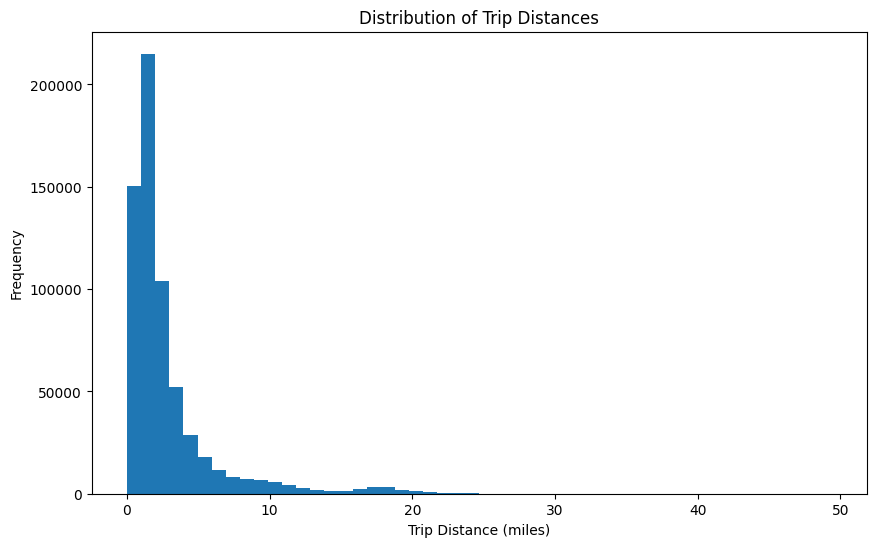

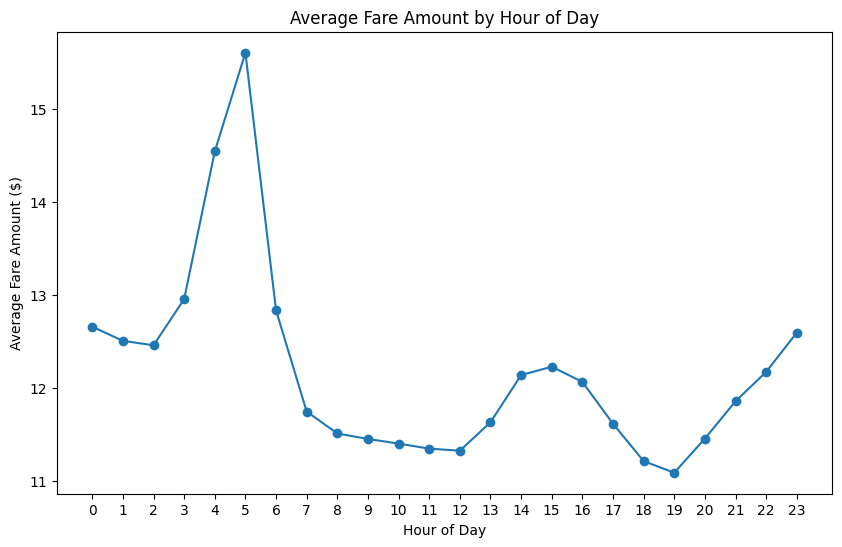

In [0]:
# CP422 - A
# Assignment 1
# Names: Pranathi Namuduri, Janya Walia, Ryan Tran, George Xie, Zhang Jiale
# Group_ID: Group_14

# Step 2: Data Ingestion
df = spark.read.csv(
    "/Volumes/workspace/default/cp422_a1/yellow_tripdata_2015-01.csv",
    header=True,
    inferSchema=True
)

df.printSchema()

display(df.limit(10))


# Step 3: Initial Data Explanation
df.select(
    "fare_amount",
    "trip_distance",
    "passenger_count"
).describe().show()

# Step 4 Data Cleaning & Preprocessing:
from pyspark.sql.functions import col

df_clean = df.dropna(
    subset=["fare_amount", "trip_distance", "passenger_count"]
)

df_clean = df_clean.filter(
    (col("fare_amount") > 0) &
    (col("trip_distance") > 0)
)

df_clean.count() 

from pyspark.sql.functions import col

df_clean = df_clean.withColumn(
    "trip_duration",
    (
        col("tpep_dropoff_datetime").cast("long")
        - col("tpep_pickup_datetime").cast("long")
    ) / 60
)

df_clean = df_clean.filter(col("trip_duration") > 0)

df_clean = df_clean.withColumn(
    "trip_speed",
    col("trip_distance") / (col("trip_duration") / 60)
)

df_clean.select(
    "trip_distance",
    "trip_duration",
    "trip_speed"
).show(10)


# Step 5 Exploratory Data Analysis (EDA):
from pyspark.sql.functions import avg

passenger_stats = df_clean.groupBy("passenger_count").agg(
    avg("fare_amount").alias("avg_fare_amount"),
    avg("trip_distance").alias("avg_trip_distance")
).orderBy("passenger_count")

passenger_stats.show()

from pyspark.sql.functions import hour, count

pickup_by_hour = df_clean.withColumn(
    "pickup_hour",
    hour("tpep_pickup_datetime")
).groupBy("pickup_hour").agg(
    count("*").alias("trip_count")
).orderBy("pickup_hour")

pickup_by_hour.show(24)

# step 5c do later

# Step 6 Data Visualization:

import matplotlib.pyplot as plt
from pyspark.sql.functions import col, hour, avg

# 6(a) Distribution of trip distances
trip_distances = (
    df_clean
    .filter(col("trip_distance") <= 50)
    .select("trip_distance")
    .sample(False, 0.05, seed=42)
    .toPandas()
)

plt.figure(figsize=(10, 6))
plt.hist(trip_distances["trip_distance"], bins=50)
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Frequency")
plt.title("Distribution of Trip Distances")
plt.show()


# 6(b) Average fare amount by hour
fare_by_hour = (
    df_clean
    .withColumn("pickup_hour", hour("tpep_pickup_datetime"))
    .groupBy("pickup_hour")
    .agg(avg("fare_amount").alias("avg_fare_amount"))
    .orderBy("pickup_hour")
)

fare_by_hour_pd = fare_by_hour.toPandas()

plt.figure(figsize=(10, 6))
plt.plot(
    fare_by_hour_pd["pickup_hour"],
    fare_by_hour_pd["avg_fare_amount"],
    marker="o"
)
plt.xlabel("Hour of Day")
plt.ylabel("Average Fare Amount ($)")
plt.title("Average Fare Amount by Hour of Day")
plt.xticks(range(24))
plt.show()
